**Писаренко Анастасия, отчет ML3**

# Задача регрессии: предсказание цены автомобиля

Цель - предсказать цену автомобиля (`price_usd`) по его характеристикам.

Сравниваются пять алгоритмов: Linear Regression, LASSO, Ridge, Random Forest Regressor и XGBoost Regressor.

Метрики: MAE и RMSE измеряются в долларах, MSE — в USD²; для этих метрик меньшее значение лучше. R² показывает долю объяснённой дисперсии; чем ближе к 1, тем лучше.

Предобработка находится внутри кросс-валидации, модель выбирается без использования тестовой выборки, потенциально раскрывающий ответ признак исключён, а некорректная балансировка таргета удалена.

In [ ]:
!pip install kagglehub xgboost

In [ ]:
from google.colab import files
files.upload()

Saving kaggle.json to kaggle.json


{'kaggle.json': b'{"username":"stlksvn","key":"b97b6ae100b37793bb70dabfe6021402"}'}

In [ ]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

In [ ]:
import kagglehub
path = kagglehub.dataset_download("chaitanyajamble/car-evaluation")
print("Path:", path)

100%|██████████| 396k/396k [00:00<00:00, 29.1MB/s]

Extracting files...
Path: /root/.cache/kagglehub/datasets/chaitanyajamble/car-evaluation/versions/1


## Импорт библиотек

Используются pandas и numpy для работы с данными, matplotlib и seaborn для визуализации. В sklearn создаются единые конвейеры из заполнения пропусков, кодирования, масштабирования и модели. Это позволяет обучать предобработку только на обучающей части каждого фолда.

In [ ]:
import glob
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, KFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBRegressor

sns.set_style("whitegrid")
RANDOM_STATE = 42

## Чтение CSV и первичная очистка

CSV-файлы сортируются для воспроизводимого выбора. Удаляются `car_id`, `customer_review_text` и `model`: идентификатор не является признаком, текст в этой работе не обрабатывается, а модель автомобиля имеет высокую кардинальность. Из даты осмотра извлекается год, затем удаляются точные дубликаты.

In [ ]:
csv_files = sorted(glob.glob(path + "/*.csv"))
if not csv_files:
    raise FileNotFoundError(f"CSV-файлы не найдены: {path}")

df = pd.read_csv(csv_files[0])
df = df.drop(columns=["car_id", "customer_review_text", "model"])
df["inspection_date"] = pd.to_datetime(df["inspection_date"], errors="coerce")
df["inspection_year"] = df["inspection_date"].dt.year
df = df.drop(columns=["inspection_date"])
df = df.drop_duplicates()

print("Форма:", df.shape)
df.head()

Форма: (10000, 19)


,brand,manufacture_year,region,buying_price_level,price_usd,maintenance_cost_level,annual_maintenance_usd,doors,seating_capacity,luggage_boot_size,safety_rating,fuel_type,transmission,engine_size_l,horsepower,mileage_km,owner_count,evaluation_class,inspection_year
0,Maruti Suzuki,2013,North America,vhigh,35415.74,med,889.71,2,more,big,high,Petrol,Manual,2.0,114.0,151369.0,1.0,acceptable,2025
1,Kia,2007,Western Europe,high,31249.33,high,1646.84,3,4,med,low,Hybrid,Automatic,1.8,86.0,87809.0,2.0,unacceptable,2023
2,Hyundai,2020,Southeast Asia,high,35062.70,high,2290.45,5more,4,med,med,Petrol,Automatic,2.3,127.0,55745.0,4.0,unacceptable,2024
3,Chevrolet,2011,Western Europe,med,23722.04,med,974.69,4,2,med,high,Petrol,Manual,2.1,111.0,212742.0,2.0,unacceptable,2025
4,Honda,2013,Africa,low,16179.22,med,1213.57,2,4,small,med,Petrol,Manual,0.9,60.0,120923.0,4.0,unacceptable,2024


Информация о датафрейме и описательная статистика
df.info() показывает типы столбцов и количество непустых значений. Видим 19 столбцов: 8 числовых (включая inspection_year) и 11 категориальных (object), включая целевую evaluation_class. Пропуски есть в annual_maintenance_usd (150), horsepower (250), mileage_km (398), owner_count (100). df.describe() даёт сводку по числовым столбцам (среднее, std, квартили).

In [ ]:
print(df.info())
print("\nОписательная статистика:")
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 19 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   brand                   10000 non-null  object 
 1   manufacture_year        10000 non-null  int64  
 2   region                  10000 non-null  object 
 3   buying_price_level      10000 non-null  object 
 4   price_usd               10000 non-null  float64
 5   maintenance_cost_level  10000 non-null  object 
 6   annual_maintenance_usd  9850 non-null   float64
 7   doors                   10000 non-null  object 
 8   seating_capacity        10000 non-null  object 
 9   luggage_boot_size       10000 non-null  object 
 10  safety_rating           10000 non-null  object 
 11  fuel_type               10000 non-null  object 
 12  transmission            10000 non-null  object 
 13  engine_size_l           10000 non-null  float64
 14  horsepower              9750 non-null  

,manufacture_year,price_usd,annual_maintenance_usd,engine_size_l,horsepower,mileage_km,owner_count,inspection_year
count,10000.000000,10000.000000,9850.000000,10000.000000,9750.000000,9602.000000,9900.000000,10000.000000
mean,2014.545500,26863.953721,1514.796417,1.630870,97.711487,150220.590398,2.016263,2024.086300
std,5.737824,18184.416118,1107.287796,0.613555,35.620608,89435.841824,1.129390,0.795308
min,2005.000000,4223.900000,250.040000,0.800000,60.000000,2093.000000,1.000000,2023.000000
25%,2010.000000,13461.935000,657.980000,1.100000,63.000000,77106.000000,1.000000,2023.000000
50%,2014.000000,22140.580000,1167.990000,1.600000,91.000000,138639.500000,2.000000,2024.000000
75%,2020.000000,35350.160000,2112.357500,2.000000,120.750000,210341.000000,3.000000,2025.000000
max,2024.000000,154064.420000,4799.890000,4.300000,274.000000,637000.000000,5.000000,2025.000000


## Проверка пропусков по столбцам

Пропуски заполняются медианой для числовых признаков и наиболее частым значением для категориальных. Все статистики рассчитываются внутри `Pipeline` отдельно на обучающей части каждого фолда. Тестовая выборка не участвует ни в заполнении пропусков, ни в масштабировании, ни в подборе гиперпараметров.

In [ ]:
print("Пропуски по столбцам:")
print(df.isnull().sum())

Пропуски по столбцам:
brand                       0
manufacture_year            0
region                      0
buying_price_level          0
price_usd                   0
maintenance_cost_level      0
annual_maintenance_usd    150
doors                       0
seating_capacity            0
luggage_boot_size           0
safety_rating               0
fuel_type                   0
transmission                0
engine_size_l               0
horsepower                250
mileage_km                398
owner_count               100
evaluation_class            0
inspection_year             0
dtype: int64


## Анализ целевой переменной

Распределение цены скошено вправо, присутствуют дорогие автомобили с большими значениями таргета. Это мотивирует проверку нелинейных моделей и отдельный анализ ошибок по ценовым сегментам. Однако древовидные модели с квадратичной функцией потерь не считаются автоматически устойчивыми к выбросам.

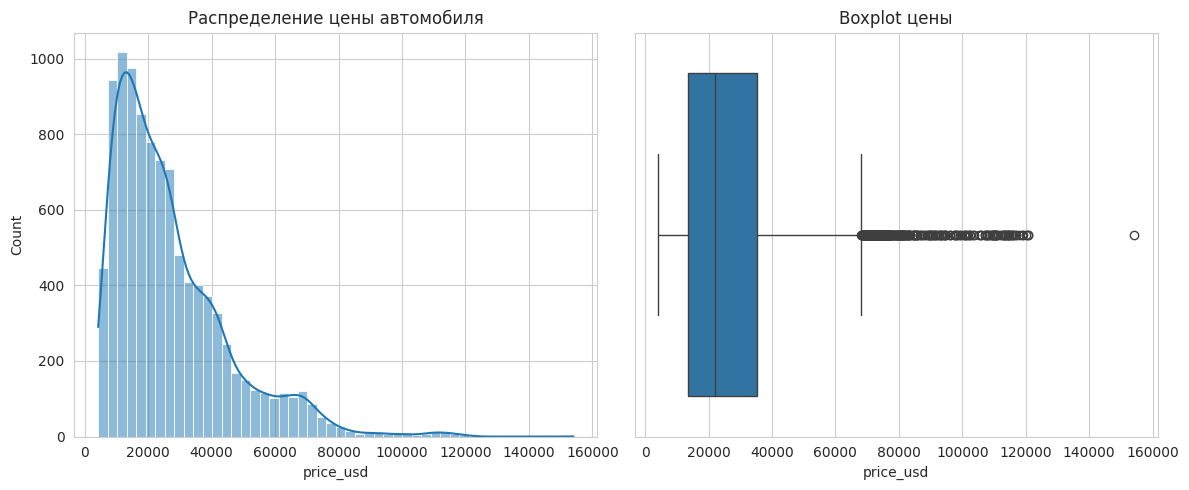

Асимметрия: 1.5270
Эксцесс:    2.9903


In [ ]:
target_col = 'price_usd'

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.histplot(df[target_col], kde=True, bins=50)
plt.title('Распределение цены автомобиля')
plt.xlabel('price_usd')

plt.subplot(1, 2, 2)
sns.boxplot(x=df[target_col])
plt.title('Boxplot цены')
plt.tight_layout()
plt.show()

print(f"Асимметрия: {df[target_col].skew():.4f}")
print(f"Эксцесс:    {df[target_col].kurt():.4f}")

## Диаграммы рассеяния: числовые признаки и цена

Диаграммы помогают качественно оценить форму связей и изменение разброса цены. Они используются для разведочного анализа, но сами по себе не доказывают преимущество конкретного алгоритма: вывод делается по результатам корректной валидации.

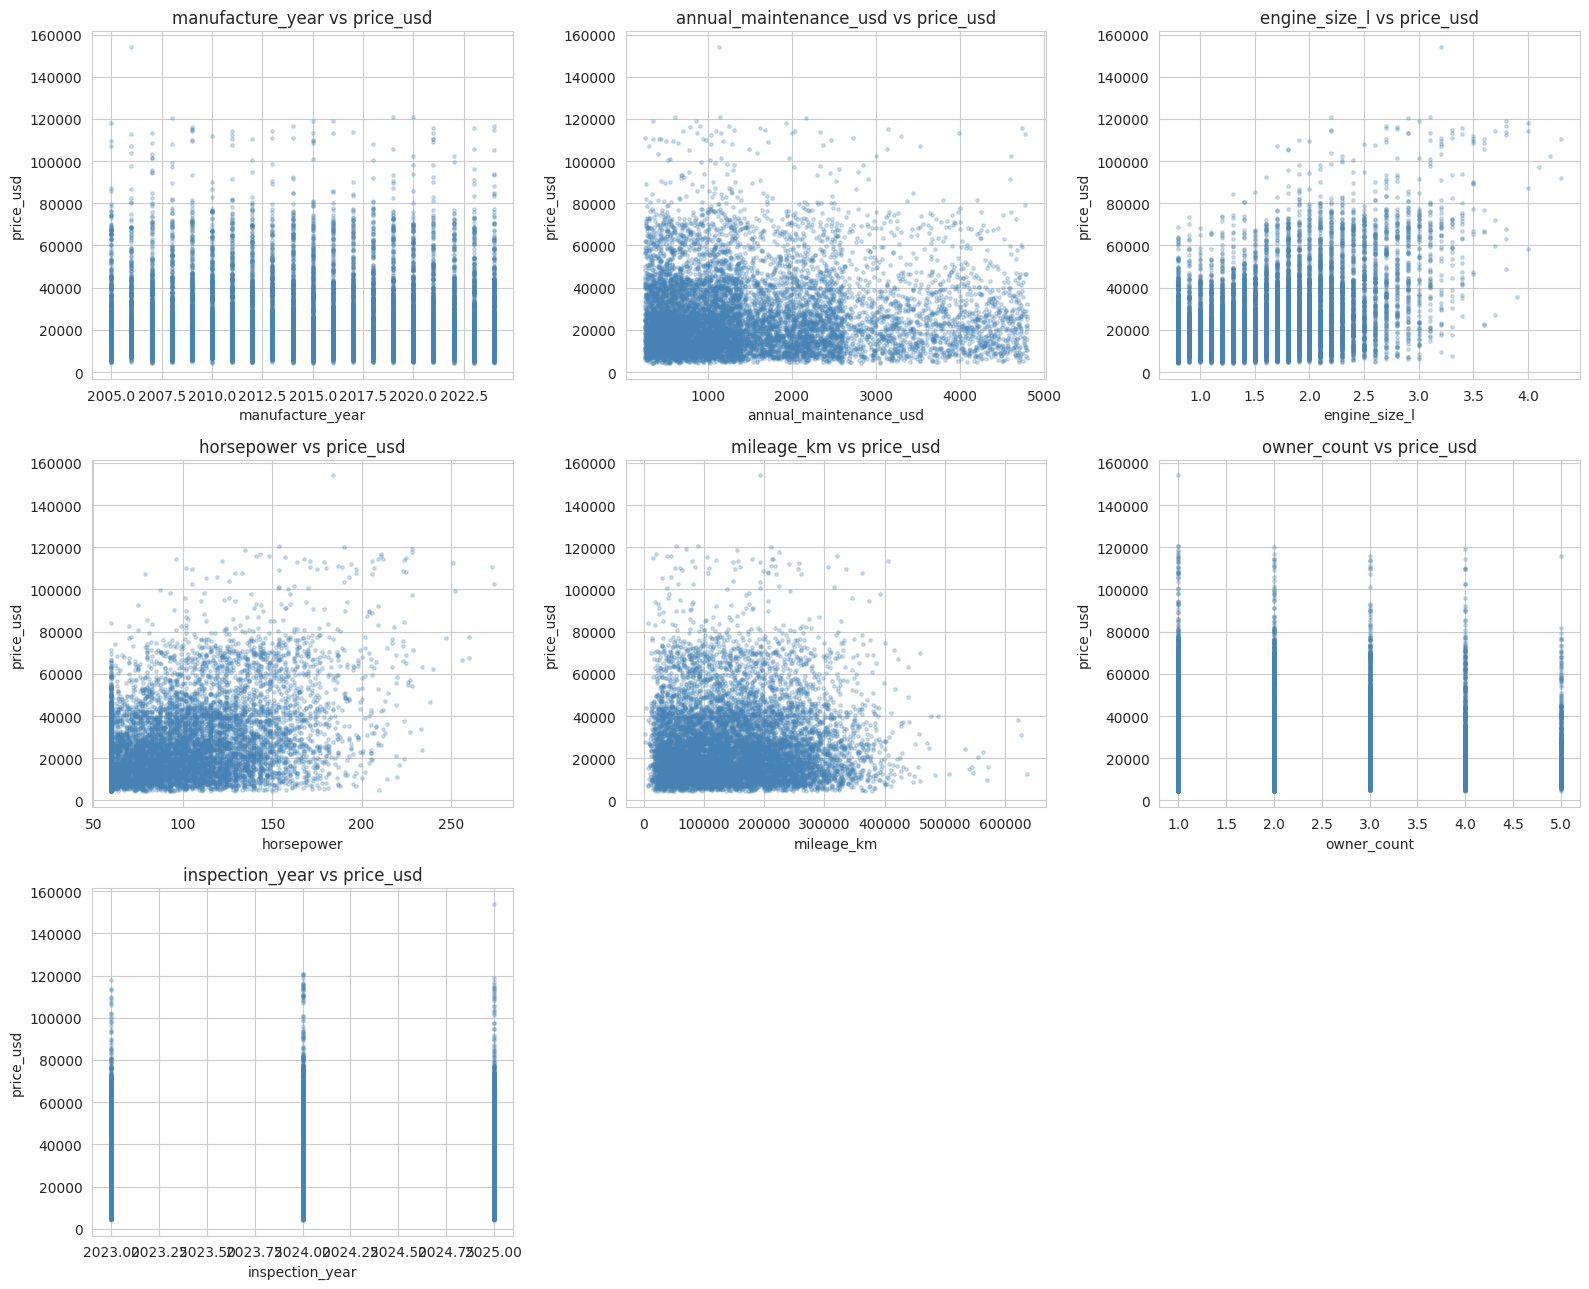

In [ ]:
num_features = ['manufacture_year', 'annual_maintenance_usd', 'engine_size_l',
                'horsepower', 'mileage_km', 'owner_count', 'inspection_year']

fig, axes = plt.subplots(3, 3, figsize=(16, 13))
axes = axes.ravel()
for i, col in enumerate(num_features):
    axes[i].scatter(df[col], df[target_col], alpha=0.25, s=6, color='steelblue')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel(target_col)
    axes[i].set_title(f'{col} vs {target_col}')
for j in range(len(num_features), len(axes)):
    axes[j].axis('off')
plt.tight_layout()
plt.show()

## Корреляционная матрица числовых признаков

Тепловая карта показывает попарные линейные корреляции Пирсона. Сильная корреляция между предикторами важна для интерпретации линейных моделей. При этом умеренная корреляция отдельных признаков с ценой не означает, что мультивариантная линейная модель обязательно недостаточна.

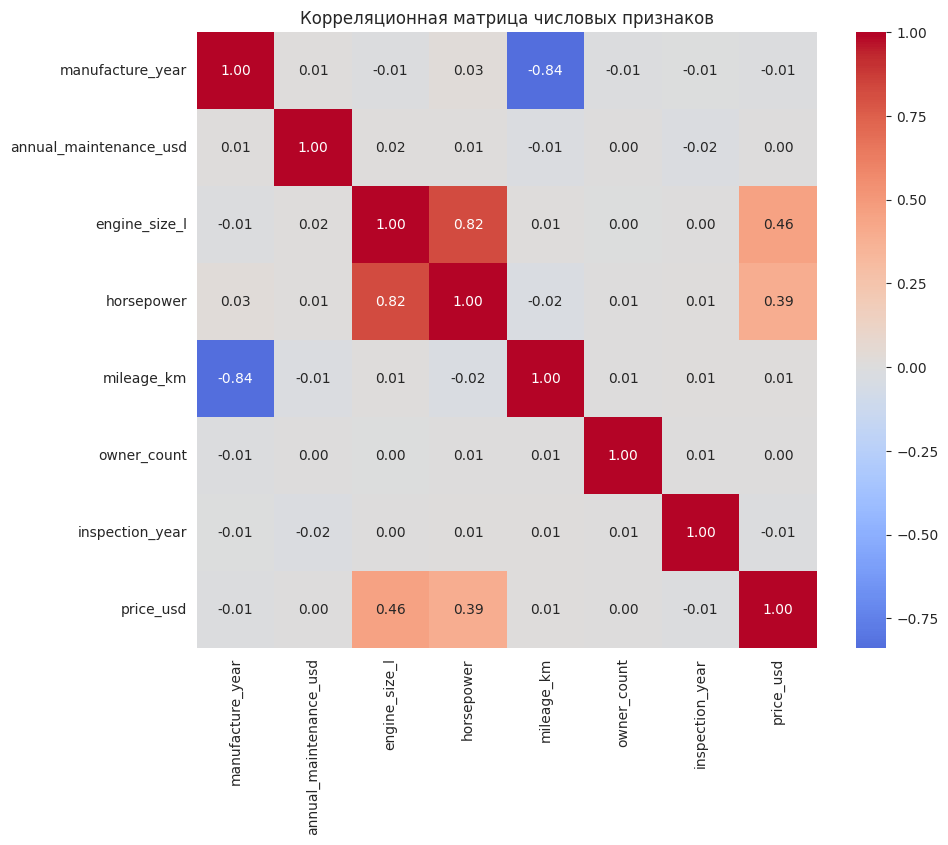

In [ ]:
plt.figure(figsize=(10, 8))
corr = df[num_features + [target_col]].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', center=0)
plt.title('Корреляционная матрица числовых признаков')
plt.show()

##Список категориальных признаков
Собираем все object-столбцы, исключая целевую (price_usd - числовая, но evaluation_class тоже object; его оставляем в списке - хотя он не будет использоваться как признак, а будет исключён позже при формировании X). Выводим список и строим bar-чарты распределения категорий. Видно, что категории несбалансированы (например, unacceptable доминирует, very_good редок).

Про evaluation_class: признак остаётся в списке категориальных
только для разведочного анализа (bar-чарты и boxplot vs цена).
В матрицу признаков X он не попадает: при формировании X
evaluation_class исключается вместе с целевой переменной.


Категориальные признаки: ['brand', 'region', 'buying_price_level', 'maintenance_cost_level', 'doors', 'seating_capacity', 'luggage_boot_size', 'safety_rating', 'fuel_type', 'transmission', 'evaluation_class']


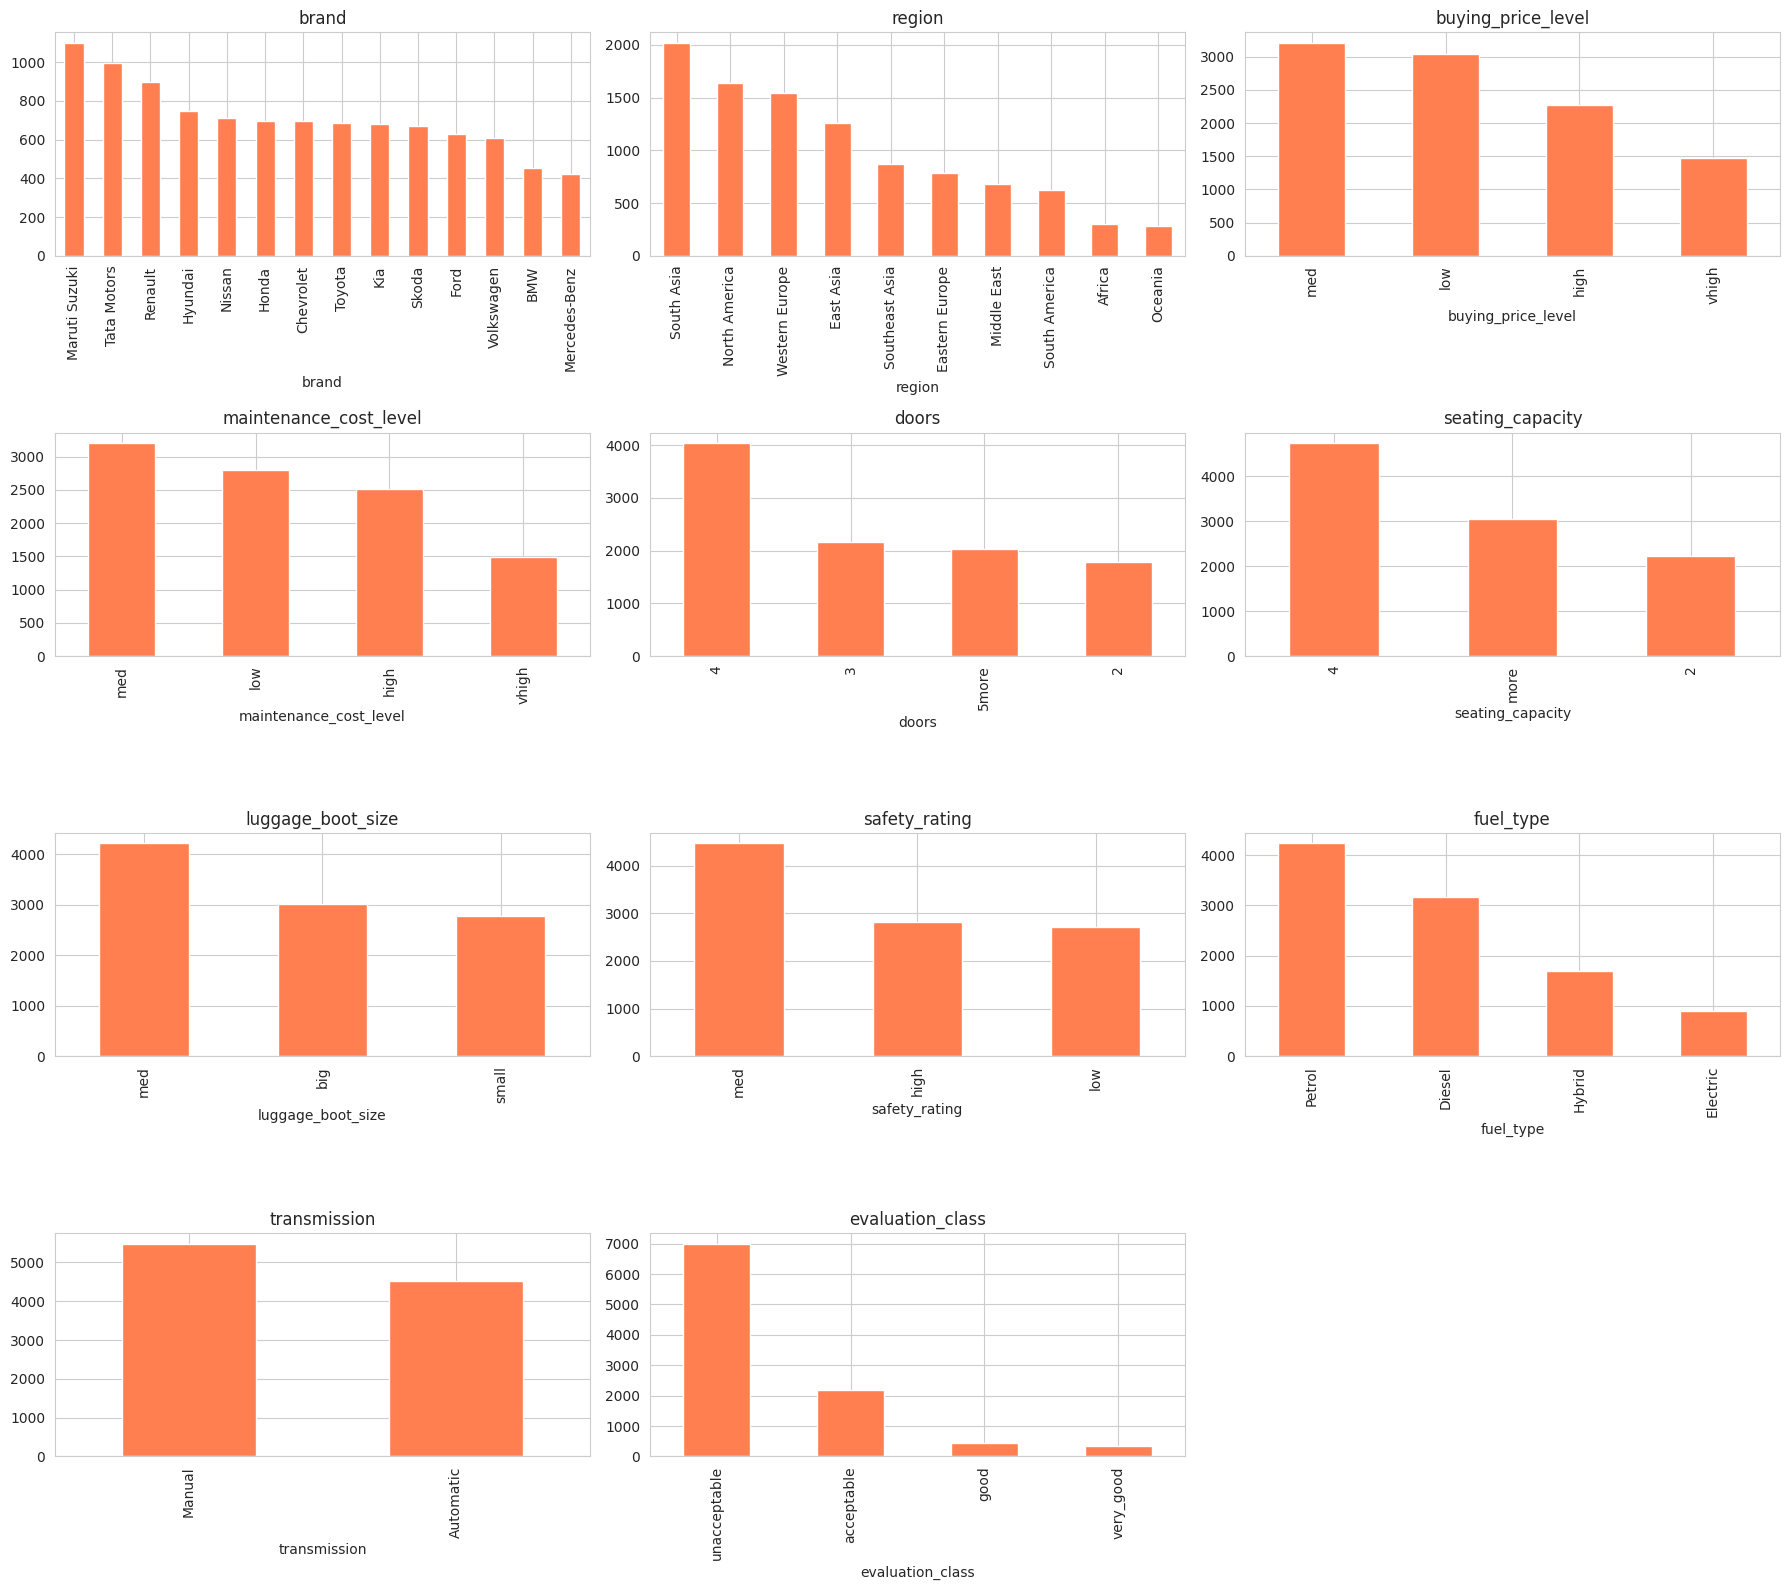

In [ ]:
cat_features = df.select_dtypes(include=['object']).columns.tolist()
cat_features = [c for c in cat_features if c != target_col]
print("Категориальные признаки:", cat_features)

n_cols = 3
n_rows = (len(cat_features) + n_cols - 1) // n_cols
fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 4 * n_rows))
axes = axes.ravel()
for i, col in enumerate(cat_features):
    df[col].value_counts().plot(kind='bar', ax=axes[i], color='coral')
    axes[i].set_title(col)
for j in range(len(cat_features), len(axes)):
    axes[j].axis('off')
plt.tight_layout()
plt.show()

## Boxplot: категориальные признаки и цена

Графики показывают различия распределения цены между категориями. Это разведочный анализ ассоциаций, а не оценка причинного эффекта или окончательная важность признаков.

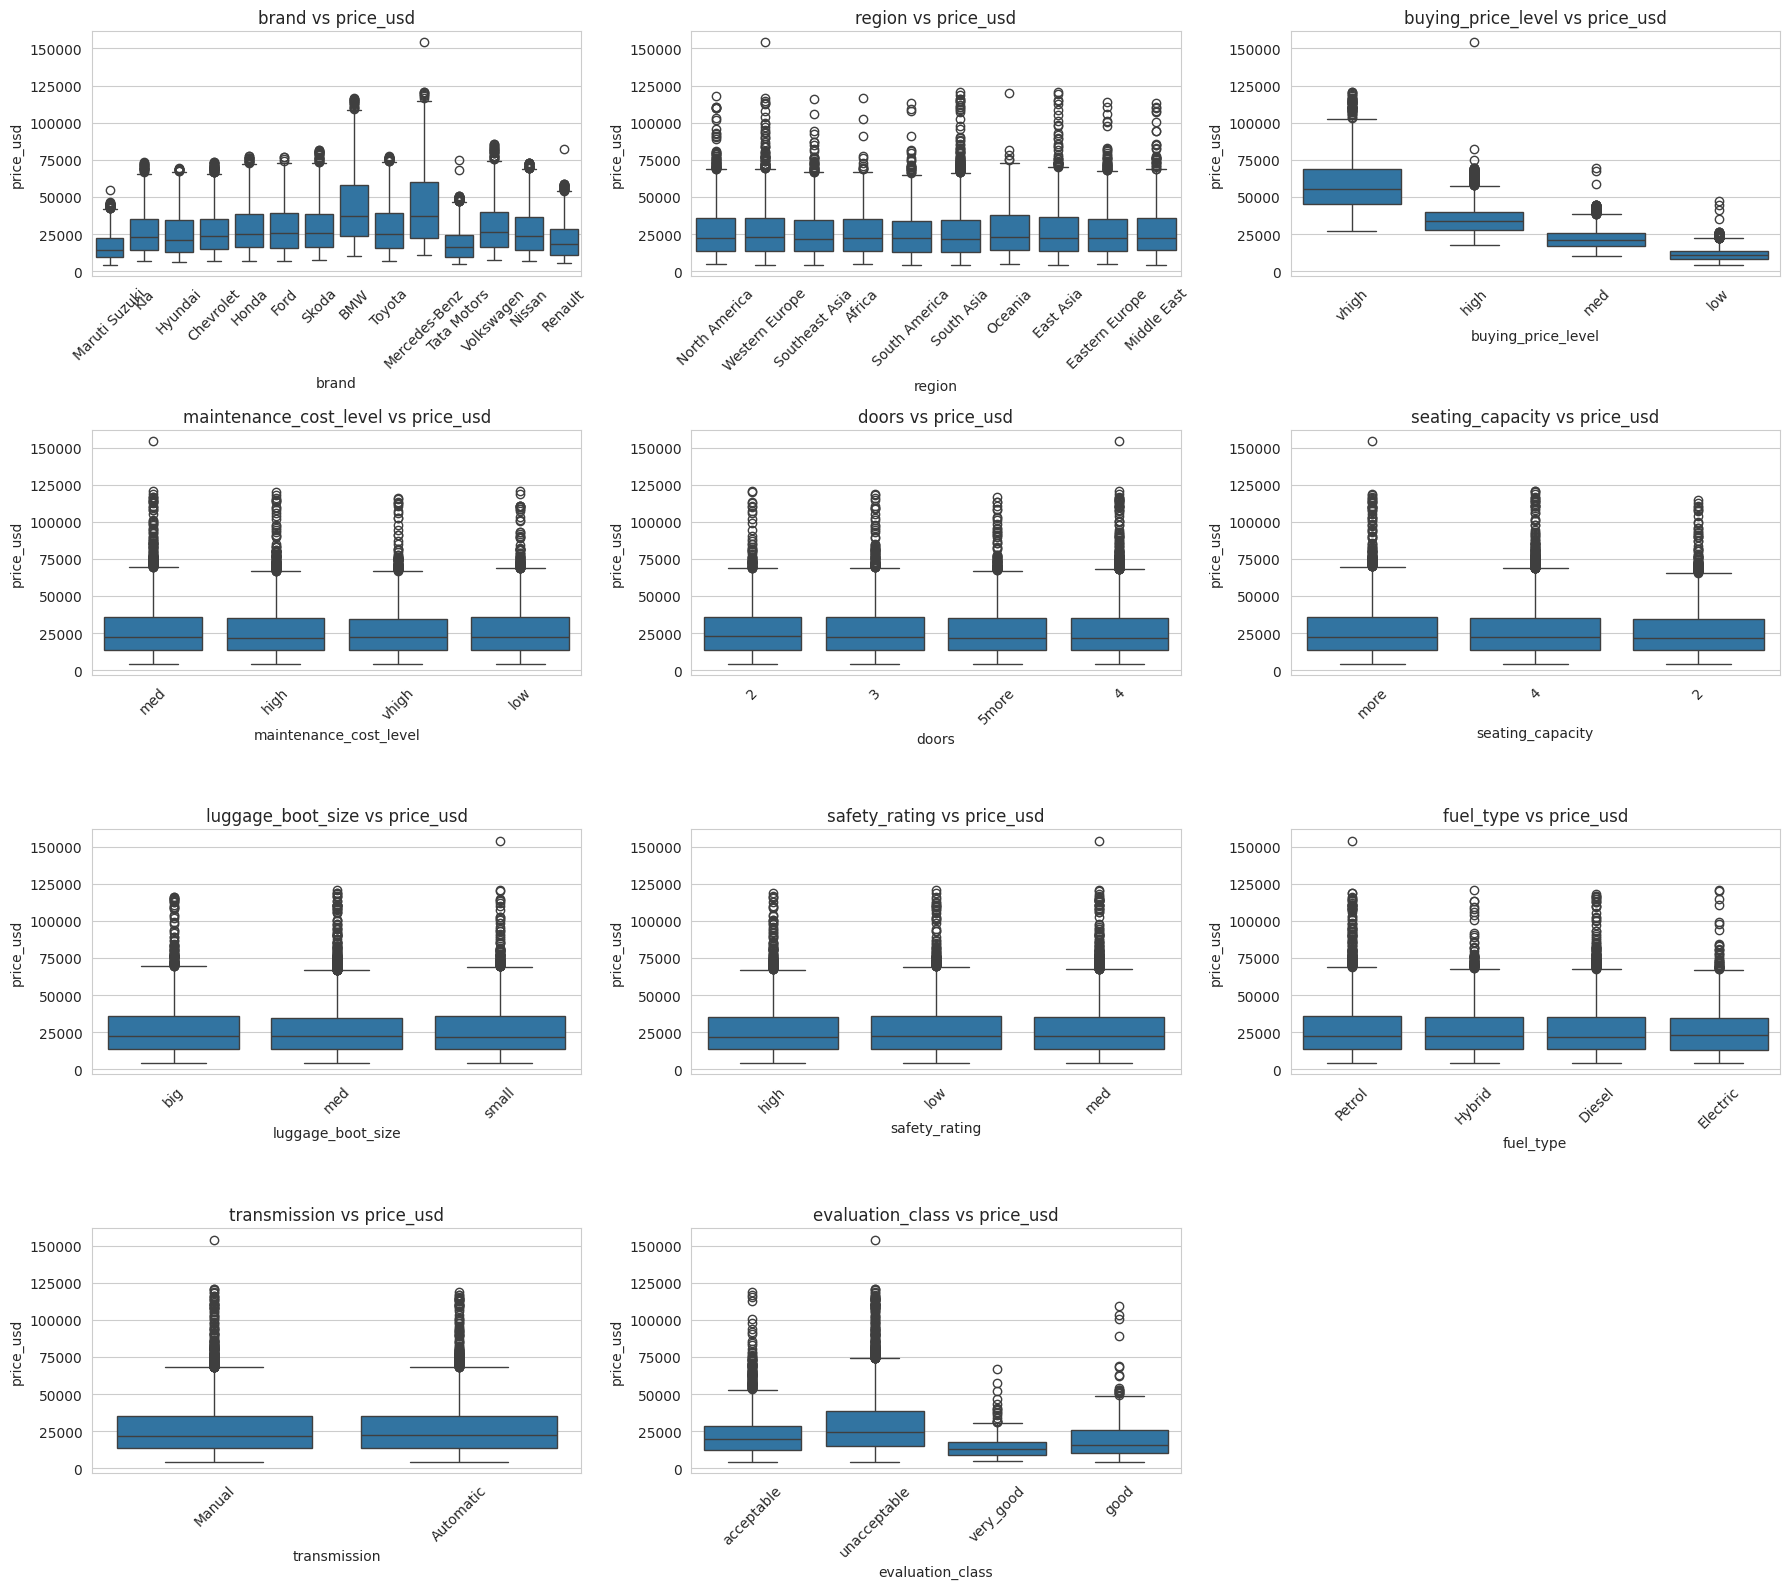

In [ ]:
fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 4 * n_rows))
axes = axes.ravel()
for i, col in enumerate(cat_features):
    sns.boxplot(x=col, y=target_col, data=df, ax=axes[i])
    axes[i].set_title(f'{col} vs {target_col}')
    axes[i].tick_params(axis='x', rotation=45)
for j in range(len(cat_features), len(axes)):
    axes[j].axis('off')
plt.tight_layout()
plt.show()

## Стратегия оценки и проверка потенциальной утечки

Квантильный `qcut` формирует примерно равные группы, поэтому исходный алгоритм не создавал новых объектов, а интерполяция синтетических автомобилей до разбиения могла бы загрязнить тест.

Признак `evaluation_class` исключается. Признак `buying_price_level` также консервативно исключается из обучения: он непосредственно описывает уровень покупной цены и может быть производным от таргета или недоступен до формирования цены. Диапазоны ниже позволяют проверить их связь; пересечение диапазонов не устраняет смысловой риск утечки.

Данные делятся на 80 % для обучения и 20 % для финальной проверки. Тестовая выборка используется только после выбора модели по кросс-валидации.

Про StandardScaler для деревьев: масштабирование включено в единый
Pipeline для всех моделей. Для линейных моделей (Linear, LASSO, Ridge)
оно необходимо, для деревьев (RF, XGBoost) не вредит: деревья
инвариантны к монотонным преобразованиям признаков, поэтому
масштабирование не меняет их решения.

In [ ]:
target_col = "price_usd"

leakage_audit = (
    df.groupby("buying_price_level")[target_col]
    .agg(["count", "min", "max", "mean"])
    .round(2)
    .sort_values("mean")
)
print("Диапазоны цены по buying_price_level (признак далее исключён):")
display(leakage_audit)

X = df.drop(columns=[target_col, "evaluation_class", "buying_price_level"])
y = df[target_col].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

num_cols = X.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = X.select_dtypes(include=["object"]).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, num_cols),
    ("cat", categorical_pipeline, cat_cols),
])


def make_pipeline(model):
    return Pipeline([
        ("preprocessor", preprocessor),
        ("model", model),
    ])


print("Форма train:", X_train.shape)
print("Форма test: ", X_test.shape)
print("Числовые признаки:", num_cols)
print("Категориальные признаки:", cat_cols)
print("Исключены: evaluation_class, buying_price_level")

Диапазоны цены по buying_price_level (признак далее исключён):


,count,min,max,mean
buying_price_level,,,,
low,3043,4223.90,47145.09,11292.49
med,3207,10226.99,69371.03,21636.77
high,2275,17513.70,154064.42,34815.56
vhigh,1475,27251.25,120842.87,58089.47


Форма train: (8000, 16)
Форма test:  (2000, 16)
Числовые признаки: ['manufacture_year', 'annual_maintenance_usd', 'engine_size_l', 'horsepower', 'mileage_km', 'owner_count', 'inspection_year']
Категориальные признаки: ['brand', 'region', 'maintenance_cost_level', 'doors', 'seating_capacity', 'luggage_boot_size', 'safety_rating', 'fuel_type', 'transmission']
Исключены: evaluation_class, buying_price_level


## Подбор гиперпараметров и сравнение моделей

Для всех моделей используются одинаковые пять перемешанных фолдов. Заполнение пропусков, One-Hot-кодирование и масштабирование выполняются заново внутри каждого фолда.

Оптимизация проводится по RMSE. Итоговая модель выбирается только по среднему CV RMSE; тестовые значения в этом этапе не участвуют. CV-оценки настроенных моделей используются для сравнения и выбора, а не как окончательная несмещённая оценка обобщающей способности - для неё служит отложенный тест.

Про критерий refit: оптимизация проводится по RMSE, а не по MAE,
поскольку RMSE сильнее штрафует большие ошибки, что критично для
задачи оценки цены. MAE и R² также считаются и выводятся в итоговой
таблице, поэтому сравнение по обоим критериям доступно.

Linear Regression: 2.5 с
LASSO: 1.2 с
Ridge: 2.0 с
Random Forest: 335.5 с
XGBoost: 9.4 с

Общее время: 350.7 с
Модель выбрана по CV до обращения к тесту: XGBoost


,Модель,CV MAE,CV RMSE,CV R2,R2 std,Параметры
0,XGBoost,11511.55,14968.98,0.3174,0.0219,"{'learning_rate': 0.05, 'max_depth': 3, 'n_est..."
1,Random Forest,11604.83,15132.33,0.3024,0.0227,"{'max_depth': 10, 'min_samples_split': 2, 'n_e..."
2,LASSO,11737.18,15247.73,0.2918,0.0206,{'alpha': 10.0}
3,Ridge,11742.46,15255.06,0.2911,0.0207,{'alpha': 10.0}
4,Linear Regression,11746.03,15256.09,0.2910,0.0208,{}


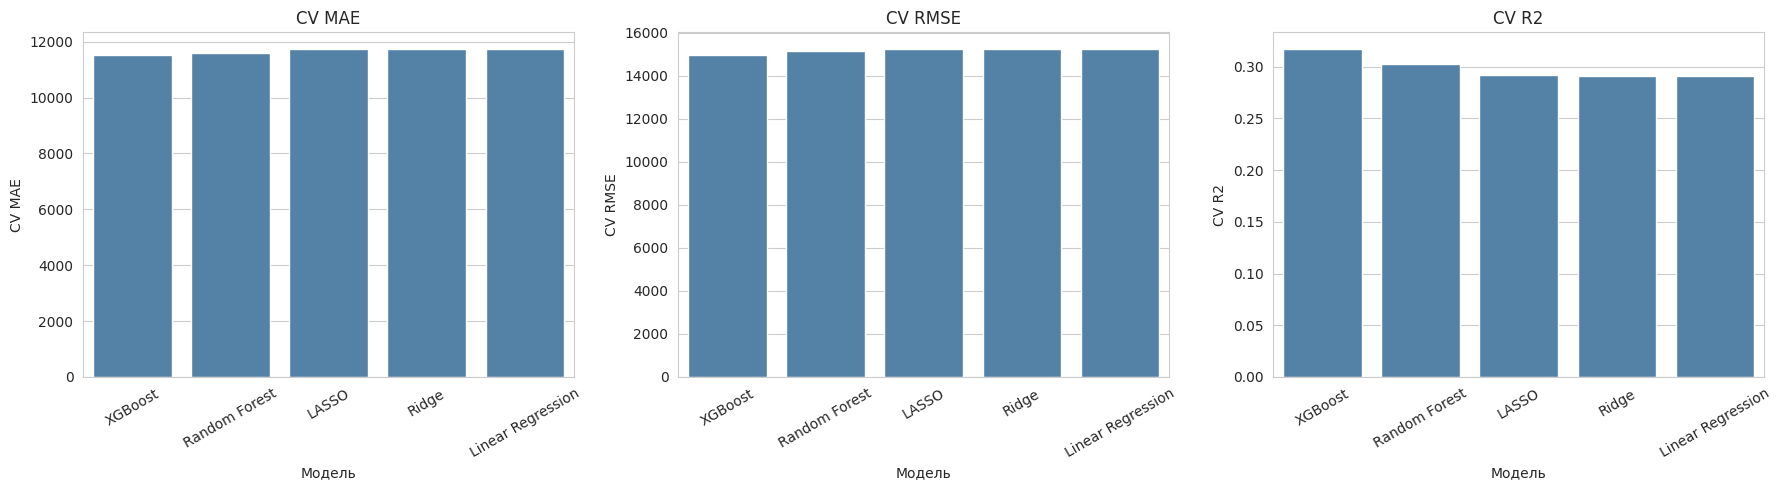

In [ ]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    "r2": "r2",
    "mae": "neg_mean_absolute_error",
    "rmse": "neg_root_mean_squared_error",
}

model_specs = {
    "Linear Regression": (LinearRegression(), {}),
    "LASSO": (
        Lasso(max_iter=100000, tol=1e-3),
        {"model__alpha": [1.0, 10.0, 100.0, 1000.0]},
    ),
    "Ridge": (
        Ridge(),
        {"model__alpha": [0.001, 0.01, 0.1, 1.0, 10.0, 100.0, 1000.0]},
    ),
    "Random Forest": (
        RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=1),
        {
            "model__n_estimators": [100, 200],
            "model__max_depth": [None, 10, 20],
            "model__min_samples_split": [2, 5],
        },
    ),
    "XGBoost": (
        XGBRegressor(
            random_state=RANDOM_STATE,
            verbosity=0,
            n_jobs=1,
            objective="reg:squarederror",
        ),
        {
            "model__n_estimators": [100, 300],
            "model__max_depth": [3, 6],
            "model__learning_rate": [0.05, 0.1],
        },
    ),
}

searches = {}
cv_rows = []
start_time = time.time()

for name, (model, param_grid) in model_specs.items():
    model_start = time.time()
    search = GridSearchCV(
        estimator=make_pipeline(model),
        param_grid=param_grid,
        scoring=scoring,
        refit="rmse",
        cv=cv,
        n_jobs=-1,
        return_train_score=False,
    )
    search.fit(X_train, y_train)
    searches[name] = search
    best_index = search.best_index_
    cv_rows.append({
        "Модель": name,
        "CV MAE": -search.cv_results_["mean_test_mae"][best_index],
        "CV RMSE": -search.cv_results_["mean_test_rmse"][best_index],
        "CV R2": search.cv_results_["mean_test_r2"][best_index],
        "R2 std": search.cv_results_["std_test_r2"][best_index],
        "Параметры": {
            key.replace("model__", ""): value
            for key, value in search.best_params_.items()
        },
    })
    print(f"{name}: {time.time() - model_start:.1f} с")

results_cv_df = (
    pd.DataFrame(cv_rows)
    .sort_values("CV RMSE")
    .reset_index(drop=True)
)

for column in ["CV MAE", "CV RMSE"]:
    results_cv_df[column] = results_cv_df[column].round(2)
for column in ["CV R2", "R2 std"]:
    results_cv_df[column] = results_cv_df[column].round(4)

best_model_name = results_cv_df.iloc[0]["Модель"]
best_search = searches[best_model_name]
final_model = best_search.best_estimator_

print()
print(f"Общее время: {time.time() - start_time:.1f} с")
print(f"Модель выбрана по CV до обращения к тесту: {best_model_name}")
display(results_cv_df)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, metric in zip(axes, ["CV MAE", "CV RMSE", "CV R2"]):
    sns.barplot(data=results_cv_df, x="Модель", y=metric, ax=ax, color="steelblue")
    ax.tick_params(axis="x", rotation=30)
    ax.set_title(metric)
plt.tight_layout()
plt.show()

## Финальная оценка на отложенной тестовой выборке

Ниже оценивается только модель, выбранная по кросс-валидации. Тестовая выборка не использовалась для подбора гиперпараметров или выбора алгоритма.

Про уровень качества: R² ≈ 0.32 на тесте — низкий, но ожидаемый
после консервативного исключения buying_price_level. Остальные
признаки слабо связаны с ценой, поэтому модель следует рассматривать
как базовый результат, а не готовый инструмент точной оценки.

In [ ]:
y_pred = final_model.predict(X_test)

test_metrics = {
    "MAE": mean_absolute_error(y_test, y_pred),
    "MSE": mean_squared_error(y_test, y_pred),
    "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
    "R2": r2_score(y_test, y_pred),
}

test_metrics_df = pd.DataFrame({
    "Модель": [best_model_name],
    "MAE": [round(test_metrics["MAE"], 2)],
    "MSE": [round(test_metrics["MSE"], 2)],
    "RMSE": [round(test_metrics["RMSE"], 2)],
    "R2": [round(test_metrics["R2"], 4)],
})

display(test_metrics_df)

best_row = results_cv_df.iloc[0]
final_summary = {
    "best_model": best_model_name,
    "best_params": {
        key.replace("model__", ""): value
        for key, value in best_search.best_params_.items()
    },
    "cv_mae": float(best_row["CV MAE"]),
    "cv_rmse": float(best_row["CV RMSE"]),
    "cv_r2": float(best_row["CV R2"]),
    "cv_r2_std": float(best_row["R2 std"]),
    "test_mae": float(test_metrics["MAE"]),
    "test_mse": float(test_metrics["MSE"]),
    "test_rmse": float(test_metrics["RMSE"]),
    "test_r2": float(test_metrics["R2"]),
}
display(final_summary)

,Модель,MAE,MSE,RMSE,R2
0,XGBoost,11539.74,2.281378e+08,15104.23,0.322


{'best_model': 'XGBoost',
 'best_params': {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 100},
 'cv_mae': 11511.55,
 'cv_rmse': 14968.98,
 'cv_r2': 0.3174,
 'cv_r2_std': 0.0219,
 'test_mae': 11539.735124433593,
 'test_mse': 228137834.01759914,
 'test_rmse': 15104.232321359439,
 'test_r2': 0.3219622582824465}

## Предсказания и фактические значения

Точки на диагонали соответствуют идеальным предсказаниям. График помогает увидеть систематические отклонения, которые нельзя описать одной сводной метрикой.

scatter предсказания vs факт на
отложенной тестовой выборке — это и есть график сравнения модели
с реальными данными на выборке, не участвовавшей в обучении.
Точки на диагонали соответствуют идеальным предсказаниям; отклонение
от диагонали показывает систематические ошибки по ценовым диапазонам.

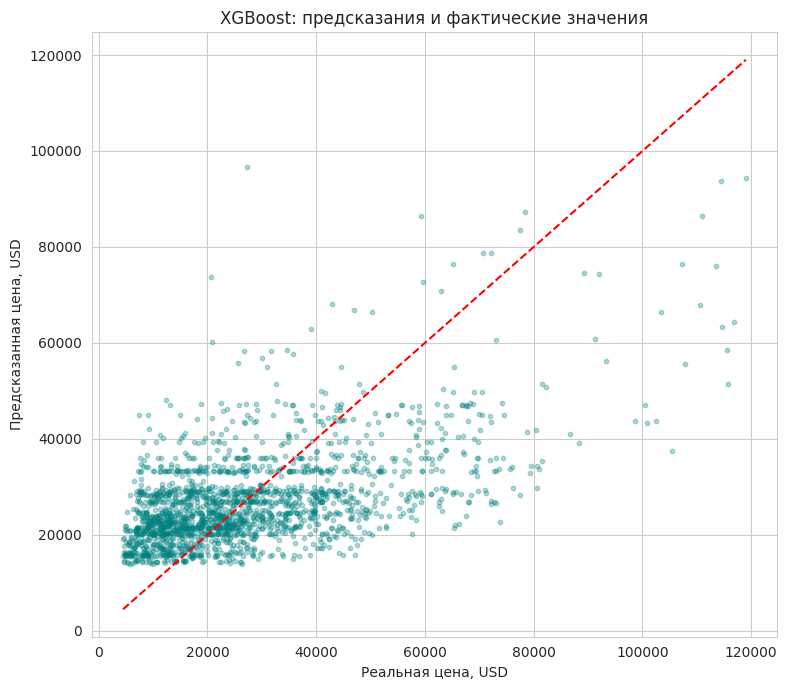

In [ ]:
plt.figure(figsize=(8, 7))
plt.scatter(y_test, y_pred, alpha=0.3, s=10, color="teal")
limits = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
plt.plot(limits, limits, "r--", lw=1.5)
plt.xlabel("Реальная цена, USD")
plt.ylabel("Предсказанная цена, USD")
plt.title(f"{best_model_name}: предсказания и фактические значения")
plt.tight_layout()
plt.show()

## Анализ остатков и ошибок по ценовым сегментам

Средний остаток описывает только общее смещение на тесте и не доказывает несмещённость модели в отдельных сегментах. Дополнительно рассчитываются MAE и RMSE по квартилям фактической цены: это позволяет проверить, где модель ошибается сильнее.

Про гетероскедастичность: разброс остатков растёт с ростом
предсказания — это типично для цен и видно на графике остатков.
Модель с квадратичной функцией потерь не устраняет этот эффект;
сегментный анализ по квартилям показывает, где ошибки больше:
в верхнем квартиле MAE достигает 20 219.95 USD.

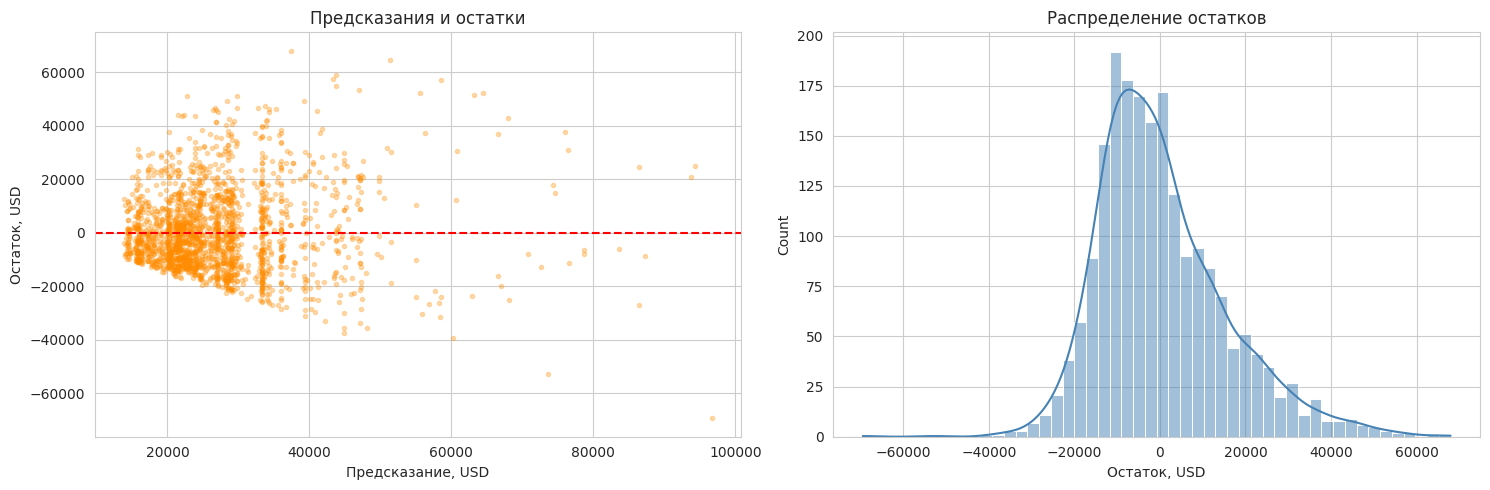

Средний остаток: 479.94 USD
Стандартное отклонение остатков: 15100.38 USD


,Сегмент,N,MAE,RMSE,Средний остаток
0,Q1 — нижний,500,12427.22,13742.79,-12427.22
1,Q2 — ниже среднего,500,6969.48,9397.46,-6246.76
2,Q3 — выше среднего,500,6542.29,8832.84,1523.42
3,Q4 — верхний,500,20219.95,23608.38,19070.31


In [ ]:
residuals = y_test - y_pred

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].scatter(y_pred, residuals, alpha=0.3, s=9, color="darkorange")
axes[0].axhline(0, color="red", linestyle="--", lw=1.5)
axes[0].set_xlabel("Предсказание, USD")
axes[0].set_ylabel("Остаток, USD")
axes[0].set_title("Предсказания и остатки")

sns.histplot(residuals, kde=True, bins=50, color="steelblue", ax=axes[1])
axes[1].set_xlabel("Остаток, USD")
axes[1].set_title("Распределение остатков")
plt.tight_layout()
plt.show()

print(f"Средний остаток: {residuals.mean():.2f} USD")
print(f"Стандартное отклонение остатков: {residuals.std():.2f} USD")

segments = pd.qcut(
    y_test,
    q=4,
    labels=["Q1 — нижний", "Q2 — ниже среднего", "Q3 — выше среднего", "Q4 — верхний"],
)
segment_rows = []
for segment in segments.cat.categories:
    mask = segments == segment
    actual = y_test.loc[mask]
    predicted = pd.Series(y_pred, index=y_test.index).loc[mask]
    segment_rows.append({
        "Сегмент": str(segment),
        "N": int(mask.sum()),
        "MAE": round(mean_absolute_error(actual, predicted), 2),
        "RMSE": round(np.sqrt(mean_squared_error(actual, predicted)), 2),
        "Средний остаток": round((actual - predicted).mean(), 2),
    })

segment_results_df = pd.DataFrame(segment_rows)
display(segment_results_df)

## Permutation importance на отложенной выборке

Важность рассчитывается для исходных признаков через готовый `Pipeline`, поэтому вклад категориального признака не дробится на отдельные One-Hot-столбцы. Значение показывает среднее ухудшение RMSE после случайной перестановки признака. Это модельно-зависимая ассоциация, а не причинный эффект; при сильной корреляции признаков важности могут распределяться между ними.

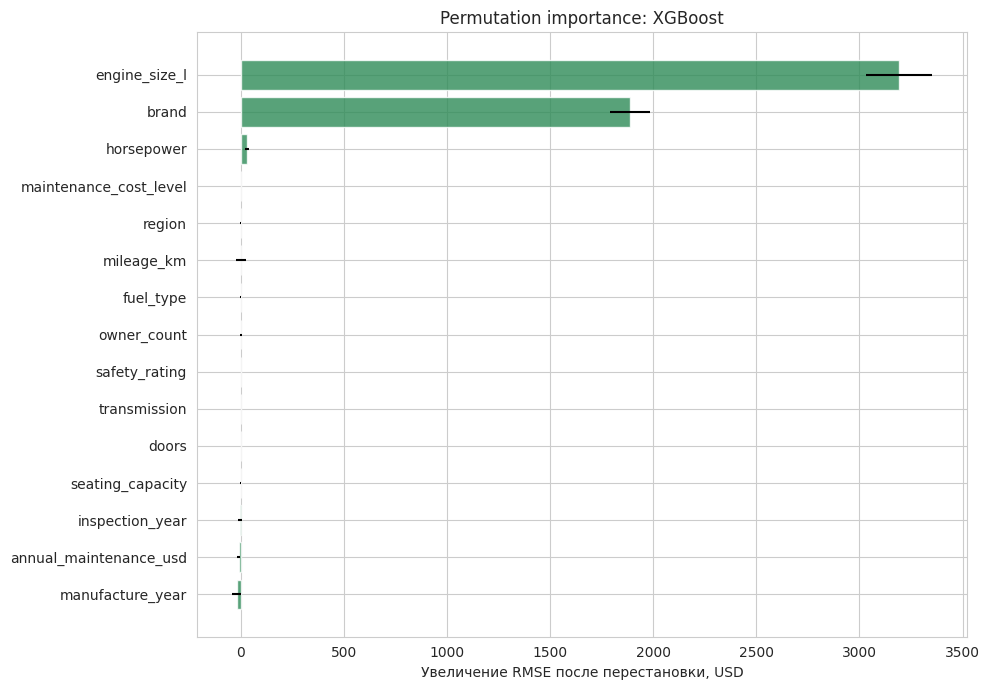

,Признак,Ухудшение RMSE,Стд. отклонение
11,engine_size_l,3191.72,161.45
0,brand,1887.71,96.03
12,horsepower,31.43,10.33
3,maintenance_cost_level,0.92,0.68
2,region,0.75,2.74
13,mileage_km,0.69,23.02
9,fuel_type,0.66,1.62
14,owner_count,0.59,4.02
8,safety_rating,0.04,0.48
10,transmission,0.00,0.00


In [ ]:
permutation = permutation_importance(
    final_model,
    X_test,
    y_test,
    scoring="neg_root_mean_squared_error",
    n_repeats=10,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

importance_df = pd.DataFrame({
    "Признак": X.columns,
    "Ухудшение RMSE": permutation.importances_mean,
    "Стд. отклонение": permutation.importances_std,
}).sort_values("Ухудшение RMSE", ascending=False)

plot_importance = importance_df.head(15).sort_values("Ухудшение RMSE")
plt.figure(figsize=(10, 7))
plt.barh(
    plot_importance["Признак"],
    plot_importance["Ухудшение RMSE"],
    xerr=plot_importance["Стд. отклонение"],
    color="seagreen",
    alpha=0.8,
)
plt.xlabel("Увеличение RMSE после перестановки, USD")
plt.title(f"Permutation importance: {best_model_name}")
plt.tight_layout()
plt.show()

display(importance_df.round(2))

## Вывод

Заполнение пропусков, кодирование и масштабирование включены в `Pipeline` и выполняются внутри каждого фолда. Признаки `evaluation_class` и потенциально раскрывающий ответ `buying_price_level` исключены. Модель и гиперпараметры выбраны по пятикратной кросс-валидации только на обучающей части; отложенная тестовая выборка использована один раз для финальной оценки выбранной модели.

По среднему CV RMSE выбран **XGBoost** с параметрами `learning_rate=0.05`, `max_depth=3`, `n_estimators=100`. На кросс-валидации получены MAE **11,511.55 USD**, RMSE **14,968.98 USD** и R² **0.3174 ± 0.0219**. На независимой тестовой выборке MAE составила **11,539.74 USD**, RMSE **15,104.23 USD**, R² **0.3220**.

Random Forest занял второе место по CV RMSE (15 133,57 USD против 14 968,98 USD у XGBoost). Разница составляет около 1,1 %, поэтому преимущество XGBoost следует считать небольшим, а не статистически доказанным.

Сегментный анализ выявил систематические ошибки: в нижнем ценовом квартиле модель в среднем завышает цену, а в верхнем - занижает её. В верхнем квартиле MAE достигла 20 219,95 USD, а средний остаток составил 19 070,31 USD. Следовательно, близкое к нулю общее среднее отклонение само по себе не означает одинаковое качество по всем ценовым диапазонам.

После консервативного исключения `buying_price_level` качество существенно ниже, чем в первоначальной версии. Поэтому прежние высокие метрики нельзя переносить на постановку без этого признака; необходимо дополнительно проверить происхождение данных и доступность каждого признака на момент прогноза. Текущая модель объясняет около 32,2 % дисперсии цены и должна рассматриваться как базовый результат, а не как готовый инструмент точной оценки автомобиля. Для улучшения качества целесообразно добавить информативные характеристики, провести feature engineering и проверить преобразование таргета с сохранением независимой финальной оценки.

Разница XGBoost и Random Forest: разница по CV RMSE ~1.1%,
поэтому преимущество XGBoost следует считать небольшим, а не
статистически доказанным. Выбор сделан по формальному критерию
CV RMSE, но интерпретировать его как безусловное превосходство
нельзя.

Возможные улучшения: низкий R² объясняется слабой связью
доступных признаков с ценой после исключения buying_price_level.
Целесообразно добавить информативные характеристики, провести
feature engineering и проверить логарифмирование таргета
(skew=1.53) с сохранением независимой финальной оценки.